# Calidad del aire en Madrid: dióxido de nitrógeno (NO₂), 2019-2025

Análisis de los datos horarios de calidad del aire publicados por el Ayuntamiento de Madrid.

**Preguntas:**
1. ¿Cómo ha evolucionado el NO₂ entre 2019 y 2025?
2. ¿Qué estaciones registran niveles más altos y más bajos?
3. ¿Hay patrones por hora del día, día de la semana o estación del año?
4. ¿Cuántas veces se superan los valores límite (UE) y recomendados (OMS)?
5. *(Con prudencia)* ¿Se aprecia algún cambio durante el confinamiento de 2020?

**Fuente de datos:** Portal de Datos Abiertos del Ayuntamiento de Madrid
- [Calidad del aire. Datos horarios desde 2001](https://datos.madrid.es/dataset/201200-0-calidad-aire-horario)
- [Calidad del aire. Estaciones de control](https://datos.madrid.es/dataset/212629-0-estaciones-control-aire)

Licencia: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/legalcode.es).

## 1. Carga y limpieza de los datos

Las funciones están en `src/carga.py`. Aquí se ejecutan paso a paso para ver qué hace cada una
y cuántos datos se pierden en cada decisión.

Antes de ejecutar este cuaderno hay que descargar los datos con `python datos/descargar_datos.py`.

In [1]:
import sys
sys.path.append("..")  # para poder importar src/ desde la carpeta notebooks/

import pandas as pd
from src import carga

### 1.1 Lectura

Hasta 2024 hay un CSV por mes; desde 2025, un único CSV (que también trae 2026 y descartamos).
Cada fila del fichero original es **un día, en una estación, para un contaminante**, con 24 columnas
de valores (`H01`…`H24`) y 24 de códigos de validación (`V01`…`V24`).

In [2]:
datos = carga.leer_csv_horarios()
print("Filas leídas:", len(datos))
datos.head(3)

Filas leídas: 346032


,PROVINCIA,MUNICIPIO,ESTACION,MAGNITUD,PUNTO_MUESTREO,ANO,MES,DIA,H01,V01,...,H20,V20,H21,V21,H22,V22,H23,V23,H24,V24
0,28,079,4,1,28079004_1_38,2019,04,01,00004,V,...,00002,V,00002,V,00004,V,00004,V,00004,V
1,28,079,4,1,28079004_1_38,2019,04,02,00003,V,...,00003,V,00004,V,00004,V,00004,V,00004,V
2,28,079,4,1,28079004_1_38,2019,04,03,00003,V,...,00006,V,00005,V,00005,V,00005,V,00004,V


### 1.2 Solo NO₂

El NO₂ es la magnitud **8**, medida en µg/m³ (Anexo II del *Intérprete de ficheros* del Ayuntamiento).

In [3]:
no2 = carga.filtrar_contaminante(datos, magnitud=8)
print("Filas de NO2 (días × estación):", len(no2))

Filas de NO2 (días × estación): 60441


### 1.3 De formato ancho a formato largo

Pasamos de «una fila = un día con 24 horas» a «una fila = una hora». Este formato (*tidy data*)
es el que permite agrupar fácilmente por hora, día de la semana, mes o año.

In [4]:
largo = carga.pasar_a_formato_largo(no2)
print("Filas en formato largo:", len(largo), "| comprobación:", len(no2) * 24)
largo.head()

Filas en formato largo: 1450584 | comprobación: 1450584


,estacion,magnitud,fecha,hora,valor,validez
0,4,8,2019-04-01,1,17.0,V
1,4,8,2019-04-02,1,22.0,V
2,4,8,2019-04-03,1,33.0,V
3,4,8,2019-04-04,1,20.0,V
4,4,8,2019-04-05,1,22.0,V


### 1.4 Solo datos válidos

Cada hora lleva un código de validación: `V` (válido) o `N` (no válido). **Los datos `N` también
traen un número**, así que no basta con quitar celdas vacías: hay que filtrar por el código.
Según la documentación, los datos se anulan por mantenimiento, averías o valores anómalos.

In [5]:
print(largo["validez"].value_counts())
validos = carga.filtrar_validos(largo)

validez
V    1434945
N      15639
Name: count, dtype: int64
Filas totales: 1450584
Filas válidas: 1434945
Descartadas:   15639 (1.1%)


Horas descartadas por año:

In [6]:
resumen = (
    largo.assign(anio=largo["fecha"].dt.year, descartada=largo["validez"] != "V")
    .groupby("anio")["descartada"]
    .agg(total="size", descartadas="sum")
)
resumen["% descartadas"] = (100 * resumen["descartadas"] / resumen["total"]).round(2)
resumen

,total,descartadas,% descartadas
anio,,,
2019,208968,1291,0.62
2020,209088,1275,0.61
2021,207840,2361,1.14
2022,205464,1866,0.91
2023,207096,3263,1.58
2024,210696,2476,1.18
2025,201432,3107,1.54


### 1.5 Fecha y hora

Según la documentación, `H24` es la media de 23:00 a 24:00. Por tanto `Hk` es la media de la hora
*k-1* a la hora *k*, y **etiquetamos cada dato con el inicio de su intervalo** (`H01` → 00:00,
`H24` → 23:00 del mismo día).

Las horas están en **hora local de Madrid** (sin zona horaria), como las publica el Ayuntamiento.

In [7]:
con_fecha = carga.anadir_fecha_hora(validos)
con_fecha.sort_values(["estacion", "fecha_hora"])[["estacion", "fecha", "hora", "fecha_hora", "valor"]].head(3)

,estacion,fecha,hora,fecha_hora,valor
2180,4,2019-01-01,1,2019-01-01 00:00:00,60.0
62621,4,2019-01-01,2,2019-01-01 01:00:00,74.0
123062,4,2019-01-01,3,2019-01-01 02:00:00,80.0


### 1.6 Nombre y tipo de estación

Se cruza con el listado oficial de estaciones (como un BUSCARV en Excel). El tipo de estación
será importante: las de **tráfico** están junto a vías con mucha circulación; las de **fondo**,
lejos de fuentes directas; las **suburbanas**, en las afueras.

In [8]:
no2_limpio = carga.anadir_estaciones(con_fecha)
print("Filas sin nombre de estación:", no2_limpio["nombre_estacion"].isna().sum())
no2_limpio = no2_limpio[["fecha_hora", "estacion", "nombre_estacion", "tipo_estacion", "valor"]]
no2_limpio.head()

Filas sin nombre de estación: 0


,fecha_hora,estacion,nombre_estacion,tipo_estacion,valor
0,2019-04-01,4,Plaza de España,Urbana tráfico,17.0
1,2019-04-02,4,Plaza de España,Urbana tráfico,22.0
2,2019-04-03,4,Plaza de España,Urbana tráfico,33.0
3,2019-04-04,4,Plaza de España,Urbana tráfico,20.0
4,2019-04-05,4,Plaza de España,Urbana tráfico,22.0


### 1.7 Comprobaciones

In [9]:
print("Filas finales:", len(no2_limpio))
print("Duplicados (misma estación y hora):", no2_limpio.duplicated(["estacion", "fecha_hora"]).sum())
print("Valores negativos:", (no2_limpio["valor"] < 0).sum())
print("Desde", no2_limpio["fecha_hora"].min(), "hasta", no2_limpio["fecha_hora"].max())
no2_limpio["valor"].describe().round(1)

Filas finales: 1434945
Duplicados (misma estación y hora): 0
Valores negativos: 0
Desde 2019-01-01 00:00:00 hasta 2025-12-31 23:00:00


count    1434945.0
mean          27.5
std           23.5
min            0.0
25%           11.0
50%           20.0
75%           38.0
max          328.0
Name: valor, dtype: float64

**Cobertura:** porcentaje de horas con dato válido sobre las horas del año, por estación.
Un 0 % significa que no hay ningún dato válido ese año.

In [10]:
horas_anio = no2_limpio.groupby(no2_limpio["fecha_hora"].dt.year)["fecha_hora"].nunique()
cobertura = (
    no2_limpio.groupby(["nombre_estacion", no2_limpio["fecha_hora"].dt.year])
    .size()
    .unstack(fill_value=0)
    .div(horas_anio)
    .mul(100)
    .round(1)
)
cobertura.columns.name = "año"
cobertura

año,2019,2020,2021,2022,2023,2024,2025
nombre_estacion,,,,,,,
Arturo Soria,99.7,99.4,99.6,71.9,99.3,99.1,98.9
Barajas Pueblo,99.8,99.8,99.5,99.2,99.0,98.9,98.2
Barrio del Pilar,99.3,98.7,99.6,98.9,98.5,98.3,98.5
Casa de Campo,99.2,99.4,95.6,98.7,94.0,97.7,97.6
Castellana,99.8,99.8,99.8,99.3,99.3,99.3,98.8
Cuatro Caminos,95.7,99.6,98.9,99.3,98.9,98.6,98.3
El Pardo,99.7,99.7,99.7,99.5,98.7,98.1,98.0
Ensanche de Vallecas,99.9,99.6,99.5,99.1,99.0,99.1,98.8
Escuelas Aguirre,95.2,98.5,97.2,99.2,99.0,98.7,98.4


Estaciones y años con **menos del 90 % de horas con dato válido**. Hay que tenerlos en cuenta
al comparar medias anuales entre estaciones (fase 3): una media calculada con muchas horas
ausentes puede no ser representativa del año completo.

In [11]:
baja_cobertura = cobertura.stack()
baja_cobertura[baja_cobertura < 90].rename("% horas válidas").to_frame()

% horas válidas
nombre_estacion  año                  
Arturo Soria     2022             71.9
Plaza de España  2020             77.3
                 2021             71.1
                 2022             75.7
Plaza del Carmen 2023             77.2
Ramón y Cajal    2023             83.7
Urb. Embajada    2025              0.0

### 1.8 Decisiones de limpieza (resumen)

| Decisión | Motivo |
|---|---|
| Periodo 2019-2025 (años completos) | 2019 como referencia previa a 2020; 2026 aún incompleto. |
| Solo NO₂ (magnitud 8) | Es el contaminante de las preguntas. |
| Solo horas con código `V` | Los datos `N` fueron anulados en la validación oficial aunque traigan número. |
| `Hk` → inicio del intervalo (k-1):00 | `H24` es la media de 23:00 a 24:00 según la documentación. |
| Hora local, sin zona horaria | Así se publica. Los días de cambio de hora tienen 23 o 25 horas (el Ayuntamiento elimina la hora repetida). |
| Se conservan las estaciones con baja cobertura | Se marcan en la tabla anterior; cómo tratarlas se decide en el análisis. |

**Limitación conocida:** la estación *Urb. Embajada* (55) no tiene ningún dato publicado en 2025,
aunque el listado oficial de estaciones indica que mide NO₂. Los datos no permiten saber el motivo.

*Los porcentajes y recuentos concretos son los que muestran las celdas de arriba.*

## 2. Criterios del análisis

**Valores de referencia para el NO₂:**

| Referencia | Media horaria | Media diaria | Media anual |
|---|---|---|---|
| Legislación vigente: [RD 102/2011, Anexo I](https://www.boe.es/buscar/act.php?id=BOE-A-2011-1645) (transpone la [Directiva 2008/50/CE](https://eur-lex.europa.eu/legal-content/ES/TXT/?uri=CELEX:32008L0050), Anexo XI) | 200 µg/m³, no más de 18 veces por año civil | — | 40 µg/m³ |
| UE desde 2030: [Directiva (UE) 2024/2881](https://eur-lex.europa.eu/legal-content/ES/TXT/?uri=CELEX:32024L2881), Anexo I, Tabla 1 | 200 µg/m³, no más de 3 veces por año | 50 µg/m³, no más de 18 veces por año | 20 µg/m³ |
| [OMS 2021](https://www.who.int/news-room/questions-and-answers/item/who-global-air-quality-guidelines) (recomendación, no obligatoria) | — | 25 µg/m³ (percentil 99: 3-4 días de superación al año) | 10 µg/m³ |

**Datos mínimos** (RD 102/2011, Anexo I, apartado J; Directiva 2008/50/CE, Anexo XI, A):
- Media diaria: al menos el 75 % de las horas (18 de 24).
- Media anual: al menos el 90 % de las horas del año. La norma excluye de ese cómputo las pérdidas
  por calibración o mantenimiento; como los datos no permiten distinguirlas, aplicamos el 90 % de forma estricta.

In [12]:
import matplotlib.pyplot as plt

FUENTE = "Fuente: Ayuntamiento de Madrid, Portal de Datos Abiertos (CC BY 4.0). Elaboración propia."

no2_limpio["anio"] = no2_limpio["fecha_hora"].dt.year

# Media anual de cada estación, junto con su cobertura (% de horas con dato válido)
medias_anuales = (
    no2_limpio.groupby(["nombre_estacion", "tipo_estacion", "anio"])["valor"]
    .mean()
    .rename("media")
    .reset_index()
)
cob_larga = cobertura.stack().rename("cobertura").reset_index().rename(columns={"año": "anio"})
medias_anuales = medias_anuales.merge(cob_larga, on=["nombre_estacion", "anio"])

# Solo cuentan las medias anuales con al menos el 90 % de horas
medias_validas = medias_anuales[medias_anuales["cobertura"] >= 90]

# Estaciones que cumplen el 90 % los siete años (grupo fijo para comparar años)
estaciones_fijas = cobertura.index[(cobertura >= 90).all(axis=1)]
print(len(estaciones_fijas), "estaciones con datos suficientes todos los años")
print("Excluidas del grupo fijo:", sorted(set(cobertura.index) - set(estaciones_fijas)))

19 estaciones con datos suficientes todos los años
Excluidas del grupo fijo: ['Arturo Soria', 'Plaza de España', 'Plaza del Carmen', 'Ramón y Cajal', 'Urb. Embajada']


## 3. ¿Cómo ha evolucionado el NO₂ entre 2019 y 2025?

Para que los años sean comparables se usa siempre el **mismo grupo de estaciones** (las que tienen
al menos el 90 % de horas válidas los siete años). La media de Madrid es la media de las medias
anuales de esas estaciones (cada estación pesa lo mismo).

In [13]:
fijas = medias_validas[medias_validas["nombre_estacion"].isin(estaciones_fijas)]

# Estaciones del grupo fijo por tipo
print(fijas.drop_duplicates("nombre_estacion")["tipo_estacion"].value_counts().to_string(), "\n")

evolucion = fijas.pivot_table(index="anio", columns="tipo_estacion", values="media", aggfunc="mean")
evolucion["Media Madrid"] = fijas.groupby("anio")["media"].mean()
evolucion.round(1)

tipo_estacion
Urbana fondo      9
Urbana tráfico    7
Suburbana         3 



tipo_estacion,Suburbana,Urbana fondo,Urbana tráfico,Media Madrid
anio,,,,
2019,20.7,32.7,40.8,33.8
2020,16.2,27.0,31.2,26.8
2021,18.0,28.5,33.0,28.5
2022,17.6,28.4,31.5,27.8
2023,17.0,27.8,30.6,27.2
2024,15.6,23.5,26.1,23.2
2025,14.7,23.0,24.3,22.2


In [14]:
cambio = (evolucion.loc[2025] / evolucion.loc[2019] - 1) * 100
print("Cambio 2019 -> 2025 (%):")
print(cambio.round(1).to_string())

Cambio 2019 -> 2025 (%):
tipo_estacion
Suburbana        -29.2
Urbana fondo     -29.7
Urbana tráfico   -40.6
Media Madrid     -34.5


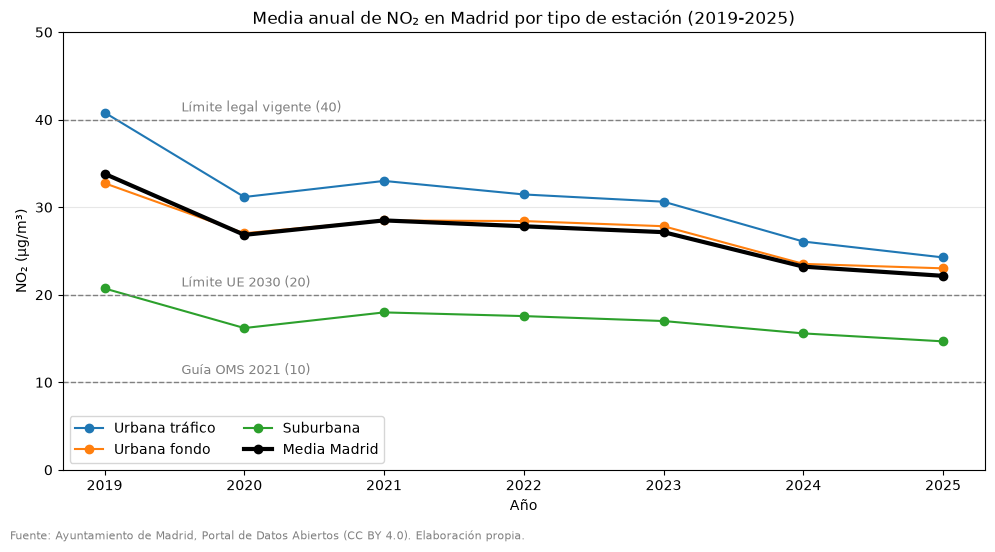

In [15]:
fig, ax = plt.subplots(figsize=(10, 5.5))

for columna in ["Urbana tráfico", "Urbana fondo", "Suburbana"]:
    ax.plot(evolucion.index, evolucion[columna], marker="o", linewidth=1.5, label=columna)
ax.plot(evolucion.index, evolucion["Media Madrid"], marker="o", linewidth=3,
        color="black", label="Media Madrid")

# Valores de referencia de la media anual
referencias = [(40, "Límite legal vigente (40)"),
               (20, "Límite UE 2030 (20)"),
               (10, "Guía OMS 2021 (10)")]
for valor, texto in referencias:
    ax.axhline(valor, color="grey", linestyle="--", linewidth=1)
    ax.text(2019.55, valor + 0.6, texto, va="bottom", fontsize=9, color="grey")

ax.set_title("Media anual de NO₂ en Madrid por tipo de estación (2019-2025)")
ax.set_xlabel("Año")
ax.set_ylabel("NO₂ (µg/m³)")
ax.set_ylim(0, 50)
ax.set_xticks(evolucion.index)
ax.legend(loc="lower left", ncol=2)
ax.grid(axis="y", alpha=0.3)
fig.text(0.01, 0.01, FUENTE, fontsize=8, color="grey")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

### Conclusión

- En las 19 estaciones con datos completos, la **media anual de NO₂ bajó de 33,8 µg/m³ en 2019
  a 22,2 µg/m³ en 2025, un 34,5 % menos**.
- La bajada no es continua: hay una **caída brusca en 2020** (26,8), un ligero repunte en 2021 (28,5),
  una etapa casi estable hasta 2023 (27,2) y un **nuevo descenso en 2024-2025**.
- Las **estaciones de tráfico** son las que más bajan (de 40,8 a 24,3 µg/m³, −40,6 %), aunque siguen
  siendo las más altas. Las suburbanas son siempre las más bajas.
- En 2025 la media de cada tipo de estación está por debajo del límite legal anual (40 µg/m³), pero las
  urbanas siguen por encima del límite que exigirá la UE en 2030 (20 µg/m³) y todas por encima de la
  guía de la OMS (10 µg/m³).

*Ojo:* son medias de grupos de estaciones. Si cada estación cumple o no los límites se ve en la
pregunta 4. Estos datos muestran **cuánto** ha bajado el NO₂, no **por qué**: no permiten atribuir la
bajada a una medida concreta.

## 4. ¿Qué estaciones registran niveles más altos y más bajos?

Se usa la media anual de cada estación, solo en los años con al menos el 90 % de horas válidas.
Primero, el último año completo (2025); después, todos los años juntos para ver si el orden se mantiene.

In [16]:
COLORES_TIPO = {"Urbana tráfico": "tab:blue", "Urbana fondo": "tab:orange", "Suburbana": "tab:green"}

ranking_2025 = (
    medias_validas[medias_validas["anio"] == 2025]
    .sort_values("media")
    .set_index("nombre_estacion")
)
print("Estaciones con media válida en 2025:", len(ranking_2025))
ranking_2025[["tipo_estacion", "media"]].round(1).iloc[::-1]

Estaciones con media válida en 2025: 23


,tipo_estacion,media
nombre_estacion,,
Plaza Elíptica,Urbana tráfico,31.7
Barajas Pueblo,Urbana fondo,29.1
Villaverde,Urbana fondo,27.5
Escuelas Aguirre,Urbana tráfico,26.7
Ensanche de Vallecas,Urbana fondo,26.3
Plaza de España,Urbana tráfico,24.8
Ramón y Cajal,Urbana tráfico,24.6
Vallecas,Urbana fondo,24.6
Farolillo,Urbana fondo,23.9


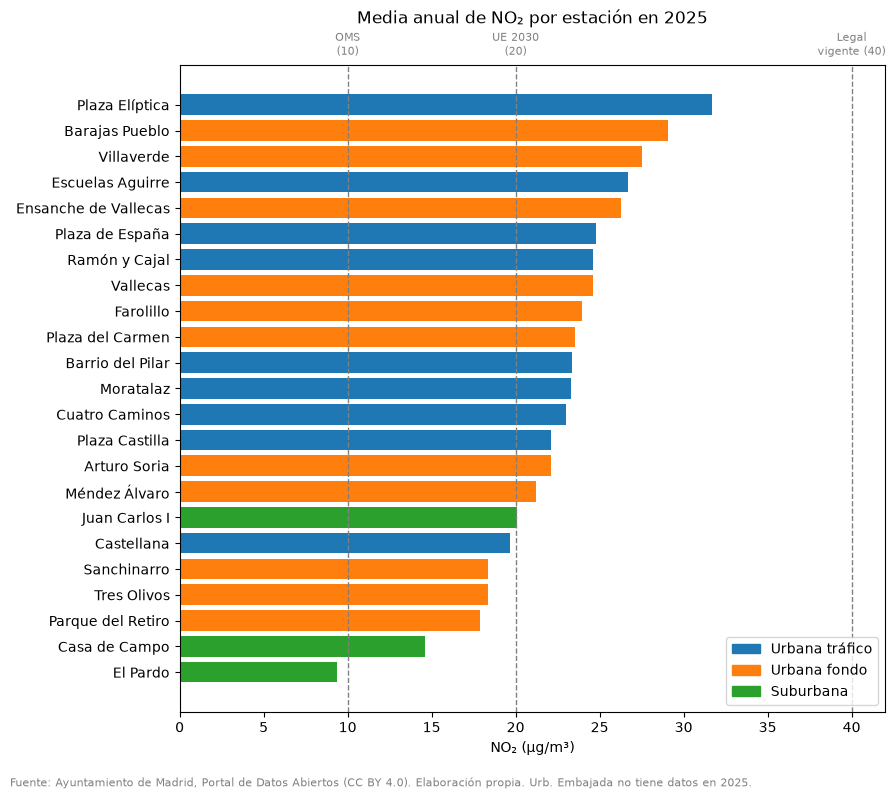

In [17]:
fig, ax = plt.subplots(figsize=(9, 8))

colores = ranking_2025["tipo_estacion"].map(COLORES_TIPO)
ax.barh(ranking_2025.index, ranking_2025["media"], color=colores)

for valor, texto in [(40, "Legal\nvigente (40)"), (20, "UE 2030\n(20)"), (10, "OMS\n(10)")]:
    ax.axvline(valor, color="grey", linestyle="--", linewidth=1)
    # get_xaxis_transform: x en datos, y en fracción del eje (1.0 = borde superior)
    ax.text(valor, 1.01, texto, fontsize=8, color="grey", ha="center", va="bottom",
            transform=ax.get_xaxis_transform())

# Leyenda manual: un rectángulo de color por tipo de estación
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=t) for t, c in COLORES_TIPO.items()], loc="lower right")

ax.set_title("Media anual de NO₂ por estación en 2025", pad=30)
ax.set_xlabel("NO₂ (µg/m³)")
ax.set_xlim(0, 42)
fig.text(0.01, 0.01, FUENTE + " Urb. Embajada no tiene datos en 2025.", fontsize=8, color="grey")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

**¿Se mantiene el orden con los años?** Mapa de calor de las medias anuales: cada fila es una
estación (ordenadas por su media 2019-2025) y cada columna un año. Las celdas en blanco son años con
menos del 90 % de horas válidas, que no se usan.

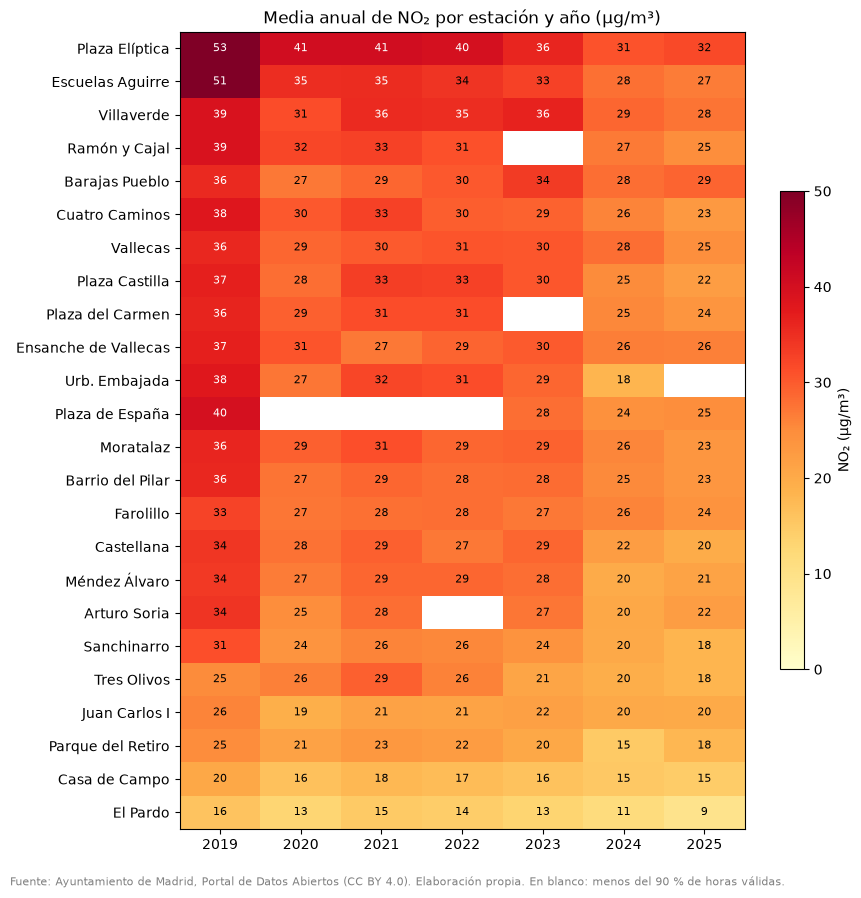

In [18]:
tabla_estaciones = medias_validas.pivot_table(index="nombre_estacion", columns="anio", values="media")
orden = tabla_estaciones.mean(axis=1).sort_values(ascending=False).index
tabla_estaciones = tabla_estaciones.loc[orden]

fig, ax = plt.subplots(figsize=(9, 9))
imagen = ax.imshow(tabla_estaciones, cmap="YlOrRd", aspect="auto", vmin=0, vmax=50)

# Escribir el valor dentro de cada celda
for i in range(tabla_estaciones.shape[0]):
    for j in range(tabla_estaciones.shape[1]):
        valor = tabla_estaciones.iloc[i, j]
        if pd.notna(valor):
            ax.text(j, i, f"{valor:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if valor > 35 else "black")

ax.set_xticks(range(len(tabla_estaciones.columns)), tabla_estaciones.columns)
ax.set_yticks(range(len(tabla_estaciones.index)), tabla_estaciones.index)
ax.set_title("Media anual de NO₂ por estación y año (µg/m³)")
fig.colorbar(imagen, ax=ax, label="NO₂ (µg/m³)", shrink=0.6)
fig.text(0.01, 0.01, FUENTE + " En blanco: menos del 90 % de horas válidas.", fontsize=8, color="grey")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

In [19]:
# Las 3 estaciones más altas y las 3 más bajas de cada año
for anio, grupo in medias_validas.groupby("anio"):
    ordenado = grupo.sort_values("media", ascending=False)["nombre_estacion"].tolist()
    print(anio, "| más altas:", ordenado[:3], "| más bajas:", ordenado[-3:])

2019 | más altas: ['Plaza Elíptica', 'Escuelas Aguirre', 'Plaza de España'] | más bajas: ['Parque del Retiro', 'Casa de Campo', 'El Pardo']
2020 | más altas: ['Plaza Elíptica', 'Escuelas Aguirre', 'Ramón y Cajal'] | más bajas: ['Juan Carlos I', 'Casa de Campo', 'El Pardo']
2021 | más altas: ['Plaza Elíptica', 'Villaverde', 'Escuelas Aguirre'] | más bajas: ['Juan Carlos I', 'Casa de Campo', 'El Pardo']
2022 | más altas: ['Plaza Elíptica', 'Villaverde', 'Escuelas Aguirre'] | más bajas: ['Juan Carlos I', 'Casa de Campo', 'El Pardo']
2023 | más altas: ['Villaverde', 'Plaza Elíptica', 'Barajas Pueblo'] | más bajas: ['Parque del Retiro', 'Casa de Campo', 'El Pardo']
2024 | más altas: ['Plaza Elíptica', 'Villaverde', 'Barajas Pueblo'] | más bajas: ['Casa de Campo', 'Parque del Retiro', 'El Pardo']
2025 | más altas: ['Plaza Elíptica', 'Barajas Pueblo', 'Villaverde'] | más bajas: ['Parque del Retiro', 'Casa de Campo', 'El Pardo']


In [20]:
m = ranking_2025["media"]
print("2025 - estaciones por encima de 40:", (m > 40).sum(), "| de 20:", (m > 20).sum(),
      "| de 10:", (m > 10).sum(), "| total:", len(m))
print("Diferencia entre la más alta y la más baja en 2025:", round(m.max() - m.min(), 1), "µg/m³")

2025 - estaciones por encima de 40: 0 | de 20: 17 | de 10: 22 | total: 23
Diferencia entre la más alta y la más baja en 2025: 22.3 µg/m³


### Conclusión

- **Plaza Elíptica** (tráfico) es la estación con la media anual más alta en 6 de los 7 años
  (en 2023 la supera Villaverde). En 2025 registra 31,7 µg/m³.
- **El Pardo** (suburbana) es la más baja todos los años; en 2025, 9,4 µg/m³, la única por debajo
  de la guía de la OMS. **Casa de Campo** (suburbana) está siempre entre las tres más bajas.
- El tipo de estación explica buena parte del orden, pero no todo: en 2025 dos estaciones de **fondo**
  (Barajas Pueblo y Villaverde) están entre las tres más altas, y una de **tráfico** (Castellana) está
  por debajo de 20 µg/m³. Estos datos no permiten saber por qué.
- En 2025 ninguna estación supera la media anual de 40 µg/m³, pero 17 de 23 están por encima de
  20 µg/m³ (límite UE 2030). En 2019, en cambio, Plaza Elíptica (53) y Escuelas Aguirre (51)
  superaban los 40 (se detalla en la pregunta 4).
- El mapa de calor muestra que **todas las estaciones bajan** entre 2019 y 2025, y que el orden
  general entre ellas se mantiene bastante estable.

## 5. ¿Hay patrones por hora del día, día de la semana o estación del año?

Aquí se comparan horas, días y meses entre sí, así que se usan **todas las horas válidas de todas
las estaciones**. Se **excluye 2020**: el confinamiento cambió por completo la rutina semanal y
distorsionaría los patrones de un año normal (ese periodo se analiza aparte en la pregunta 5).

Recordatorio: la hora indica el **inicio** de cada intervalo (8 = media de 8:00 a 9:00), en hora local.

In [21]:
patrones = no2_limpio[no2_limpio["anio"] != 2020].copy()

patrones["hora_dia"] = patrones["fecha_hora"].dt.hour        # 0..23
patrones["dia_semana"] = patrones["fecha_hora"].dt.dayofweek  # 0 = lunes ... 6 = domingo
patrones["mes"] = patrones["fecha_hora"].dt.month

# Tipo de día: laborable (lunes-viernes), sábado o domingo
patrones["tipo_dia"] = "Laborable (lun-vie)"
patrones.loc[patrones["dia_semana"] == 5, "tipo_dia"] = "Sábado"
patrones.loc[patrones["dia_semana"] == 6, "tipo_dia"] = "Domingo"

perfil_horario = patrones.pivot_table(index="hora_dia", columns="tipo_dia", values="valor", aggfunc="mean")
perfil_horario = perfil_horario[["Laborable (lun-vie)", "Sábado", "Domingo"]]
perfil_horario.round(1)

C:\Users\sergi\AppData\Local\Temp\ipykernel_2172\1480928891.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  patrones["dia_semana"] = patrones["fecha_hora"].dt.dayofweek  # 0 = lunes ... 6 = domingo


tipo_dia,Laborable (lun-vie),Sábado,Domingo
hora_dia,,,
0,30.2,33.4,32.8
1,25.1,29.7,28.7
2,20.8,25.3,24.4
3,18.1,21.8,20.3
4,17.1,19.8,17.8
5,18.2,19.2,16.8
6,25.1,21.3,17.9
7,38.4,25.0,20.4
8,44.9,27.2,21.0


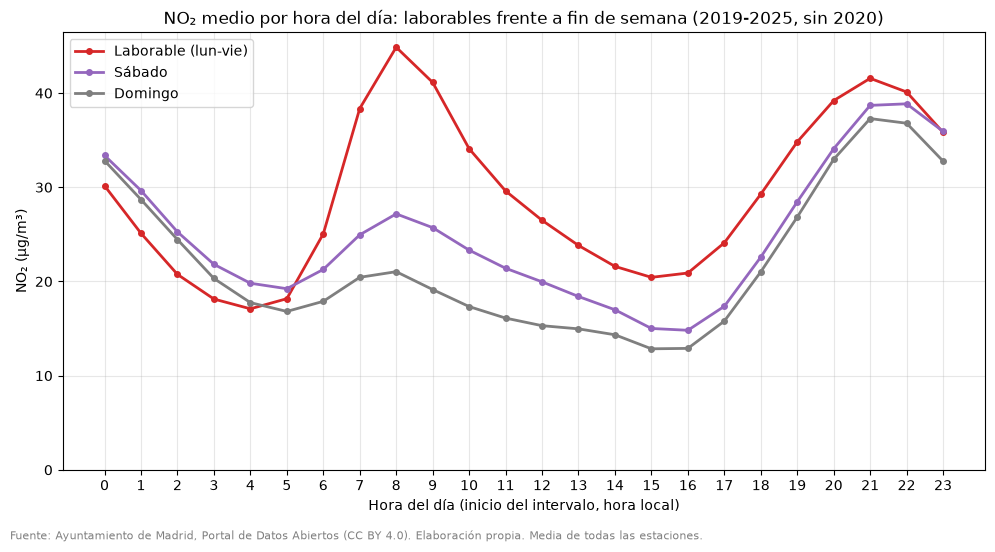

In [22]:
fig, ax = plt.subplots(figsize=(10, 5.5))

for columna, color in zip(perfil_horario.columns, ["tab:red", "tab:purple", "tab:gray"]):
    ax.plot(perfil_horario.index, perfil_horario[columna], marker="o", markersize=4,
            linewidth=2, color=color, label=columna)

ax.set_title("NO₂ medio por hora del día: laborables frente a fin de semana (2019-2025, sin 2020)")
ax.set_xlabel("Hora del día (inicio del intervalo, hora local)")
ax.set_ylabel("NO₂ (µg/m³)")
ax.set_xticks(range(0, 24))
ax.set_ylim(0, None)
ax.legend()
ax.grid(alpha=0.3)
fig.text(0.01, 0.01, FUENTE + " Media de todas las estaciones.", fontsize=8, color="grey")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

In [23]:
# Horas punta de cada tipo de día y diferencias
for columna in perfil_horario.columns:
    serie = perfil_horario[columna]
    print(f"{columna}: máximo {serie.max():.1f} a las {serie.idxmax()}h | mínimo {serie.min():.1f} a las {serie.idxmin()}h")

laborable = perfil_horario["Laborable (lun-vie)"]
domingo = perfil_horario["Domingo"]
print(f"\nA las 8h, un laborable tiene {laborable[8] / domingo[8]:.1f} veces más NO2 que un domingo "
      f"({laborable[8]:.1f} frente a {domingo[8]:.1f})")

Laborable (lun-vie): máximo 44.9 a las 8h | mínimo 17.1 a las 4h
Sábado: máximo 38.9 a las 22h | mínimo 14.8 a las 16h
Domingo: máximo 37.3 a las 21h | mínimo 12.8 a las 15h

A las 8h, un laborable tiene 2.1 veces más NO2 que un domingo (44.9 frente a 21.0)


**Día de la semana y mes del año:**

In [24]:
NOMBRES_DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
NOMBRES_MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

por_dia = patrones.groupby("dia_semana")["valor"].mean()
por_mes = patrones.groupby("mes")["valor"].mean()

# Estación del año (meteorológica): invierno = dic-feb, primavera = mar-may, etc.
ESTACION_ANIO = {12: "Invierno", 1: "Invierno", 2: "Invierno",
                 3: "Primavera", 4: "Primavera", 5: "Primavera",
                 6: "Verano", 7: "Verano", 8: "Verano",
                 9: "Otoño", 10: "Otoño", 11: "Otoño"}
COLORES_ESTACION = {"Invierno": "tab:blue", "Primavera": "tab:green", "Verano": "tab:red", "Otoño": "tab:brown"}
por_estacion_anio = patrones.groupby(patrones["mes"].map(ESTACION_ANIO))["valor"].mean()

print("Por día de la semana:", dict(zip(NOMBRES_DIAS, por_dia.round(1))))
print("Por mes:", dict(zip(NOMBRES_MESES, por_mes.round(1))))
print("Por estación del año:", por_estacion_anio.round(1).to_dict())

Por día de la semana: {'Lun': 28.3, 'Mar': 30.3, 'Mié': 29.0, 'Jue': 29.6, 'Vie': 28.8, 'Sáb': 24.8, 'Dom': 21.9}
Por mes: {'Ene': 41.0, 'Feb': 38.5, 'Mar': 26.9, 'Abr': 21.8, 'May': 18.0, 'Jun': 19.9, 'Jul': 20.3, 'Ago': 19.6, 'Sep': 24.7, 'Oct': 32.2, 'Nov': 30.9, 'Dic': 37.2}
Por estación del año: {'Invierno': 38.9, 'Otoño': 29.3, 'Primavera': 22.2, 'Verano': 19.9}


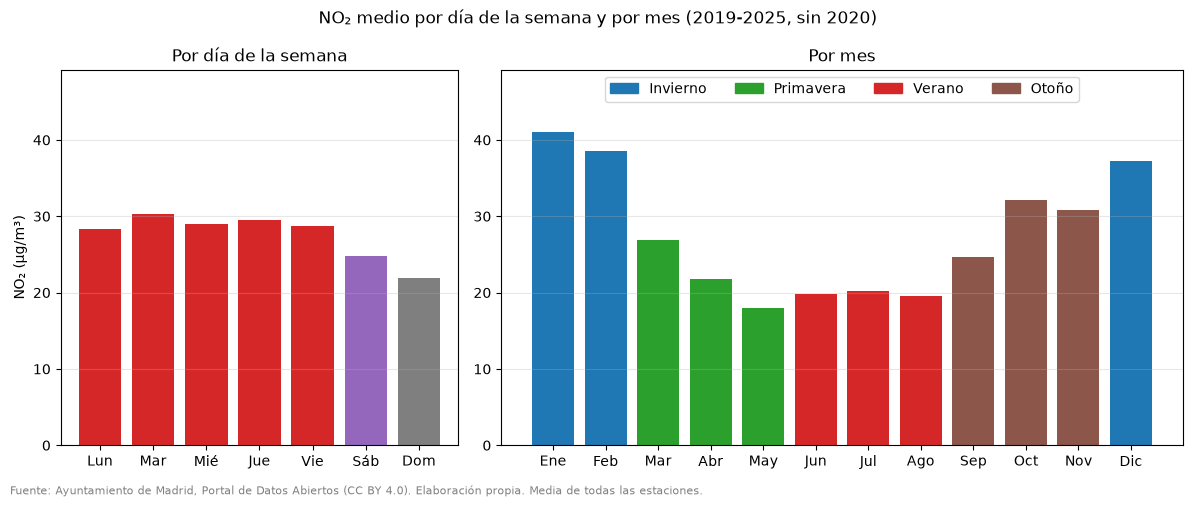

In [25]:
from matplotlib.patches import Patch

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [7, 12]})

ax1.bar(NOMBRES_DIAS, por_dia, color=["tab:red"] * 5 + ["tab:purple", "tab:gray"])
ax1.set_title("Por día de la semana")
ax1.set_ylabel("NO₂ (µg/m³)")

colores_mes = [COLORES_ESTACION[ESTACION_ANIO[m]] for m in por_mes.index]
ax2.bar(NOMBRES_MESES, por_mes, color=colores_mes)
ax2.set_title("Por mes")
ax2.legend(handles=[Patch(color=c, label=e) for e, c in COLORES_ESTACION.items()], loc="upper center", ncol=4)
for ax in (ax1, ax2):
    ax.set_ylim(0, por_mes.max() * 1.2)  # misma escala en los dos paneles
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("NO₂ medio por día de la semana y por mes (2019-2025, sin 2020)")
fig.text(0.01, 0.01, FUENTE + " Media de todas las estaciones.", fontsize=8, color="grey")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

### Conclusión

- **Hora del día:** en los días laborables hay **dos picos**, uno por la mañana (máximo de 44,9 µg/m³
  en la hora de 8:00 a 9:00) y otro por la noche (41,6 a las 21h). El mínimo es de madrugada (17,1 a las 4h).
- **Fin de semana:** el pico de la mañana **casi desaparece**. A las 8h, un laborable tiene 2,1 veces
  más NO₂ que un domingo (44,9 frente a 21,0). En cambio, el pico de la noche se mantiene en los tres
  tipos de día (entre 37 y 42 µg/m³).
- **Día de la semana:** de lunes a viernes la media está entre 28,3 y 30,3 µg/m³; baja el sábado (24,8)
  y es mínima el domingo (21,9).
- **Mes y estación del año:** el NO₂ es mucho más alto en **invierno** (media de 38,9 µg/m³; enero, 41,0)
  que en **verano** (19,9; mayo es el mes más bajo, con 18,0). La media de invierno es casi el doble que la de verano.

El patrón semanal y el pico de la mañana de los laborables **coinciden** con el horario de la actividad
laboral. Estos datos no incluyen tráfico ni meteorología, así que no permiten comprobar las causas del
pico nocturno ni de la diferencia entre invierno y verano.

## 6. ¿Cuántas veces se superan los valores límite y recomendados?

Los límites se aplican **a cada estación por separado** (no a la media de Madrid). Se analizan tres escalas:

1. **Horaria:** horas por encima de 200 µg/m³ (legal vigente: máximo 18 al año; UE 2030: máximo 3).
2. **Diaria:** días por encima de 50 µg/m³ (UE 2030: máximo 18 al año) y de 25 µg/m³ (OMS: 3-4 días al año).
   Solo cuentan los días con al menos 18 horas válidas.
3. **Anual:** media anual por encima de 40 (legal vigente), 20 (UE 2030) y 10 µg/m³ (OMS).
   Solo cuentan los años con al menos el 90 % de horas válidas.

### 6.1 Horas por encima de 200 µg/m³

In [26]:
horas_200 = (
    no2_limpio[no2_limpio["valor"] > 200]
    .groupby(["anio", "nombre_estacion"])
    .size()
    .rename("horas > 200")
)
print("Total de horas por encima de 200 µg/m³ (todas las estaciones):")
print(horas_200.groupby("anio").sum().reindex(range(2019, 2026), fill_value=0).to_string())
print("\nEstación-año con más de 18 horas (incumple el límite vigente):", (horas_200 > 18).sum())
print("Estación-año con más de 3 horas (no cumpliría el límite UE 2030):", (horas_200 > 3).sum())
horas_200.reset_index().sort_values("horas > 200", ascending=False).head(10)

Total de horas por encima de 200 µg/m³ (todas las estaciones):
anio
2019    96
2020    13
2021    11
2022     1
2023     0
2024     0
2025     0

Estación-año con más de 18 horas (incumple el límite vigente): 1
Estación-año con más de 3 horas (no cumpliría el límite UE 2030): 10


,anio,nombre_estacion,horas > 200
5,2019,Plaza Elíptica,47
7,2019,Ramón y Cajal,15
3,2019,Ensanche de Vallecas,8
4,2019,Escuelas Aguirre,7
1,2019,Barrio del Pilar,6
13,2020,Ramón y Cajal,6
12,2020,Plaza Elíptica,5
14,2021,Cuatro Caminos,5
8,2019,Sanchinarro,5
0,2019,Arturo Soria,4


### 6.2 Días por encima de 50 y de 25 µg/m³

In [27]:
no2_limpio["dia"] = no2_limpio["fecha_hora"].dt.normalize()  # fecha sin la hora

diarias = (
    no2_limpio.groupby(["nombre_estacion", "dia"])["valor"]
    .agg(media="mean", horas="size")
    .reset_index()
)
print("Días-estación totales:", len(diarias))
diarias = diarias[diarias["horas"] >= 18]  # criterio del 75 % de horas
print("Días-estación con al menos 18 horas válidas:", len(diarias))
diarias["anio"] = diarias["dia"].dt.year

dias_por_estacion = diarias.groupby(["anio", "nombre_estacion"]).agg(
    dias_validos=("media", "size"),
    dias_mas_50=("media", lambda s: (s > 50).sum()),
    dias_mas_25=("media", lambda s: (s > 25).sum()),
)

resumen_dias = dias_por_estacion.groupby("anio").agg(
    estaciones=("dias_validos", "size"),
    media_dias_mas_50=("dias_mas_50", "mean"),
    estaciones_mas_18_dias_50=("dias_mas_50", lambda s: (s > 18).sum()),
    media_dias_mas_25=("dias_mas_25", "mean"),
    minimo_dias_mas_25=("dias_mas_25", "min"),
    estaciones_mas_4_dias_25=("dias_mas_25", lambda s: (s > 4).sum()),
)
resumen_dias.round(1)

Días-estación totales: 60398
Días-estación con al menos 18 horas válidas: 60043


,estaciones,media_dias_mas_50,estaciones_mas_18_dias_50,media_dias_mas_25,minimo_dias_mas_25,estaciones_mas_4_dias_25
anio,,,,,,
2019,24,76.0,23,222.1,62,24
2020,24,43.5,20,162.0,36,24
2021,24,35.8,19,179.6,26,24
2022,24,31.4,19,180.7,27,24
2023,24,34.1,19,171.1,16,24
2024,24,17.9,11,135.9,7,24
2025,23,12.1,6,127.6,4,22


### 6.3 Media anual frente a 40, 20 y 10 µg/m³

In [28]:
superan_anual = medias_validas.groupby("anio").agg(
    estaciones=("media", "size"),
    mas_de_40=("media", lambda s: (s > 40).sum()),
    mas_de_20=("media", lambda s: (s > 20).sum()),
    mas_de_10=("media", lambda s: (s > 10).sum()),
)
print("Estaciones que superan el límite legal anual (40):")
print(medias_validas[medias_validas["media"] > 40][["anio", "nombre_estacion", "media"]].round(1).to_string(index=False))
superan_anual

Estaciones que superan el límite legal anual (40):
 anio  nombre_estacion  media
 2019 Escuelas Aguirre   51.5
 2019   Plaza Elíptica   53.4
 2020   Plaza Elíptica   40.5
 2021   Plaza Elíptica   40.6


,estaciones,mas_de_40,mas_de_20,mas_de_10
anio,,,,
2019,24,2,23,24
2020,23,1,20,23
2021,23,1,21,23
2022,22,0,20,22
2023,22,0,20,22
2024,24,0,18,24
2025,23,0,17,22


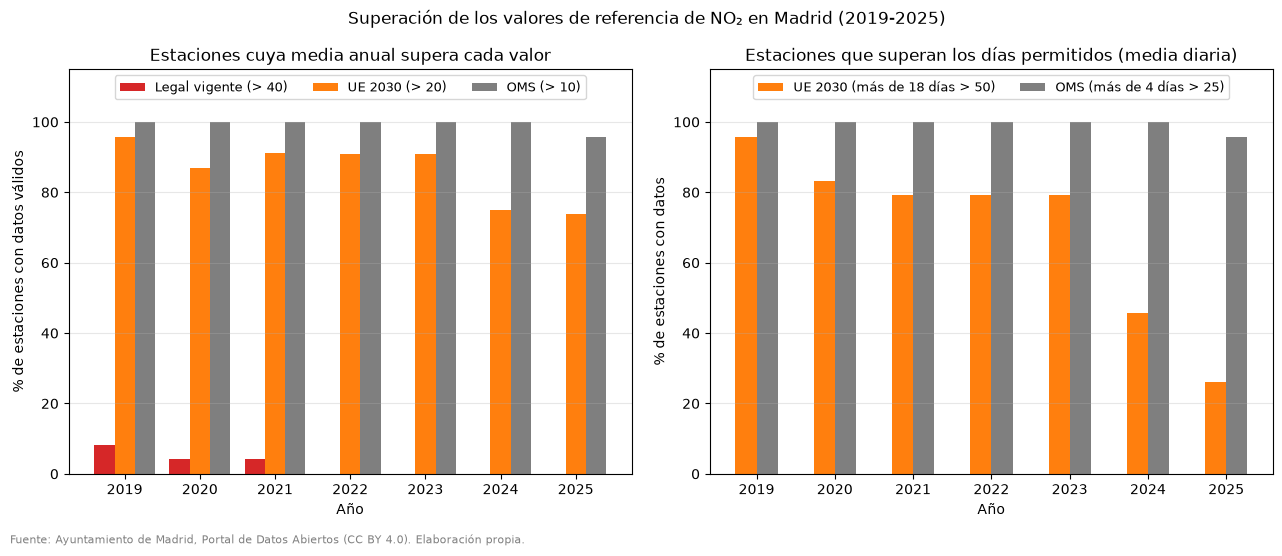

In [29]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

# Izquierda: % de estaciones que superan cada valor anual
pct = superan_anual[["mas_de_40", "mas_de_20", "mas_de_10"]].div(superan_anual["estaciones"], axis=0) * 100
ancho = 0.27
etiquetas = {"mas_de_40": "Legal vigente (> 40)", "mas_de_20": "UE 2030 (> 20)", "mas_de_10": "OMS (> 10)"}
for k, (col, color) in enumerate(zip(pct.columns, ["tab:red", "tab:orange", "tab:gray"])):
    ax1.bar(pct.index + (k - 1) * ancho, pct[col], width=ancho, color=color, label=etiquetas[col])
ax1.set_title("Estaciones cuya media anual supera cada valor")
ax1.set_ylabel("% de estaciones con datos válidos")
ax1.set_xticks(pct.index)
ax1.set_ylim(0, 115)
ax1.legend(loc="upper center", ncol=3, fontsize=9)

# Derecha: % de estaciones que superan el número de días permitido
pct_dias = pd.DataFrame({
    "UE 2030 (más de 18 días > 50)": resumen_dias["estaciones_mas_18_dias_50"],
    "OMS (más de 4 días > 25)": resumen_dias["estaciones_mas_4_dias_25"],
}).div(resumen_dias["estaciones"], axis=0) * 100
for k, (col, color) in enumerate(zip(pct_dias.columns, ["tab:orange", "tab:gray"])):
    ax2.bar(pct_dias.index + (k - 0.5) * ancho, pct_dias[col], width=ancho, color=color, label=col)
ax2.set_title("Estaciones que superan los días permitidos (media diaria)")
ax2.set_ylabel("% de estaciones con datos")
ax2.set_xticks(pct_dias.index)
ax2.set_ylim(0, 115)
ax2.legend(loc="upper center", ncol=2, fontsize=9)

for ax in (ax1, ax2):
    ax.set_xlabel("Año")
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("Superación de los valores de referencia de NO₂ en Madrid (2019-2025)")
fig.text(0.01, 0.01, FUENTE, fontsize=8, color="grey")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

### Conclusión

**Legislación vigente (40 µg/m³ anual; 200 µg/m³ horario, máximo 18 horas):**
- Media anual: solo se supera en **Escuelas Aguirre (2019)** y **Plaza Elíptica (2019, 2020 y 2021)**.
  Desde 2022, ninguna estación supera los 40 µg/m³.
- Horas por encima de 200 µg/m³: 96 en 2019, 13 en 2020, 11 en 2021, 1 en 2022 y **ninguna de 2023 a 2025**.
  Solo un caso supera las 18 horas permitidas: Plaza Elíptica en 2019 (47 horas).

**Límites UE 2030 (20 µg/m³ anual; 50 µg/m³ diario, máximo 18 días; 200 horario, máximo 3 horas):**
- Media anual: en 2025, **17 de 23 estaciones** superan los 20 µg/m³ (en 2019 eran 23 de 24).
- Días por encima de 50 µg/m³: el número de estaciones que superan los 18 días baja de 23 (2019) a **6 (2025)**.
- Horas por encima de 200: 10 casos de estación-año superan las 3 horas, todos entre 2019 y 2021.

**Guía de la OMS (10 µg/m³ anual; 25 µg/m³ diario, 3-4 días al año):**
- En 2025, **22 de 23 estaciones** superan la media anual de 10 µg/m³ (todas menos El Pardo), y también
  22 de 23 superan los 4 días con media diaria por encima de 25 µg/m³.

En resumen: según estos datos, **desde 2022 ninguna estación supera los límites legales vigentes** de NO₂
(la evaluación oficial del cumplimiento corresponde a las administraciones). Con los niveles de 2025, la
mayoría de estaciones **todavía superarían los límites que exigirá la UE en 2030**, y casi todas están
por encima de las recomendaciones de la OMS.

*Limitación:* en los años con poca cobertura de una estación (ver apartado 1.7) faltan días, así que
los recuentos de horas y días de esa estación pueden estar por debajo de los reales.